# Insurance Claim Fraud Detection — Full EDA + Machine Learning Model

**Dataset:** fraud_oracle.csv

**Rows:** 15,420 | **Columns:** 33

In this notebook, we perform a complete End-to-End project on vehicle insurance claims — from Business Understanding, Data Cleaning and Exploratory Data Analysis (EDA), to finding **which factors lead to fraud**, reducing the 33 columns to the **12 most important ones**, building a machine learning model and saving it for a FastAPI + HTML web page.

# 1.Business Understanding

**Context:**
An insurance company receives thousands of vehicle claims. A small number of them are fraud (fake or exaggerated claims). Checking every claim by hand is slow and expensive, so the company wants to know which claims look suspicious and should be investigated first.

**Target column:** `FraudFound_P` → 1 = fraud claim, 0 = genuine claim

**Business Goals:**

   1.To find out how common fraud is in the data.

   2.To find which columns have the strongest relation with fraud.

   3.To find which groups of customers / policies lead to fraud.

   4.To reduce 33 columns to only 12 inputs (a user will type these on a web page).

   5.To build a model that gives a fraud risk score for a new claim, and serve it through an API.

# 2.Data Overview

In [ ]:
# upload the csv file (only needed in Google Colab; on your laptop keep the csv next to this notebook)
import os
if not os.path.exists("fraud_oracle.csv"):
    from google.colab import files
    uploaded = files.upload()

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [2]:
# chart style: clean look, light grid, one main colour (blue) and one highlight colour (orange)
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e8e7e1", "axes.axisbelow": True,
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left", "font.size": 10,
})
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#c9c8c1"

In [3]:
# Load dataset
df = pd.read_csv("fraud_oracle.csv", encoding="utf-8-sig")

In [4]:
# Returns the first rows
df.head()

,Month,WeekOfMonth,DayOfWeek,Make,AccidentArea,DayOfWeekClaimed,MonthClaimed,WeekOfMonthClaimed,Sex,MaritalStatus,Age,Fault,PolicyType,VehicleCategory,VehiclePrice,FraudFound_P,PolicyNumber,RepNumber,Deductible,DriverRating,Days_Policy_Accident,Days_Policy_Claim,PastNumberOfClaims,AgeOfVehicle,AgeOfPolicyHolder,PoliceReportFiled,WitnessPresent,AgentType,NumberOfSuppliments,AddressChange_Claim,NumberOfCars,Year,BasePolicy
0,Dec,5,Wednesday,Honda,Urban,Tuesday,Jan,1,Female,Single,21,Policy Holder,Sport - Liability,Sport,more than 69000,0,1,12,300,1,more than 30,more than 30,none,3 years,26 to 30,No,No,External,none,1 year,3 to 4,1994,Liability
1,Jan,3,Wednesday,Honda,Urban,Monday,Jan,4,Male,Single,34,Policy Holder,Sport - Collision,Sport,more than 69000,0,2,15,400,4,more than 30,more than 30,none,6 years,31 to 35,Yes,No,External,none,no change,1 vehicle,1994,Collision
2,Oct,5,Friday,Honda,Urban,Thursday,Nov,2,Male,Married,47,Policy Holder,Sport - Collision,Sport,more than 69000,0,3,7,400,3,more than 30,more than 30,1,7 years,41 to 50,No,No,External,none,no change,1 vehicle,1994,Collision
3,Jun,2,Saturday,Toyota,Rural,Friday,Jul,1,Male,Married,65,Third Party,Sedan - Liability,Sport,20000 to 29000,0,4,4,400,2,more than 30,more than 30,1,more than 7,51 to 65,Yes,No,External,more than 5,no change,1 vehicle,1994,Liability
4,Jan,5,Monday,Honda,Urban,Tuesday,Feb,2,Female,Single,27,Third Party,Sport - Collision,Sport,more than 69000,0,5,3,400,1,more than 30,more than 30,none,5 years,31 to 35,No,No,External,none,no change,1 vehicle,1994,Collision


In [5]:
# Returns the last rows
df.tail()

,Month,WeekOfMonth,DayOfWeek,Make,AccidentArea,DayOfWeekClaimed,MonthClaimed,WeekOfMonthClaimed,Sex,MaritalStatus,Age,Fault,PolicyType,VehicleCategory,VehiclePrice,FraudFound_P,PolicyNumber,RepNumber,Deductible,DriverRating,Days_Policy_Accident,Days_Policy_Claim,PastNumberOfClaims,AgeOfVehicle,AgeOfPolicyHolder,PoliceReportFiled,WitnessPresent,AgentType,NumberOfSuppliments,AddressChange_Claim,NumberOfCars,Year,BasePolicy
15415,Nov,4,Friday,Toyota,Urban,Tuesday,Nov,5,Male,Married,35,Policy Holder,Sedan - Collision,Sedan,20000 to 29000,1,15416,5,400,4,more than 30,more than 30,2 to 4,6 years,31 to 35,No,No,External,none,no change,1 vehicle,1996,Collision
15416,Nov,5,Thursday,Pontiac,Urban,Friday,Dec,1,Male,Married,30,Policy Holder,Sedan - Liability,Sport,30000 to 39000,0,15417,11,400,3,more than 30,more than 30,more than 4,6 years,31 to 35,No,No,External,more than 5,no change,3 to 4,1996,Liability
15417,Nov,5,Thursday,Toyota,Rural,Friday,Dec,1,Male,Single,24,Policy Holder,Sedan - Collision,Sedan,20000 to 29000,1,15418,4,400,4,more than 30,more than 30,more than 4,5 years,26 to 30,No,No,External,1 to 2,no change,1 vehicle,1996,Collision
15418,Dec,1,Monday,Toyota,Urban,Thursday,Dec,2,Female,Married,34,Third Party,Sedan - All Perils,Sedan,20000 to 29000,0,15419,6,400,4,more than 30,more than 30,none,2 years,31 to 35,No,No,External,more than 5,no change,1 vehicle,1996,All Perils
15419,Dec,2,Wednesday,Toyota,Urban,Thursday,Dec,3,Male,Single,21,Policy Holder,Sedan - Collision,Sedan,20000 to 29000,1,15420,3,400,4,more than 30,more than 30,none,5 years,26 to 30,No,No,External,1 to 2,no change,1 vehicle,1996,Collision


In [6]:
df.columns.tolist()

['Month', 'WeekOfMonth', 'DayOfWeek', 'Make', 'AccidentArea', 'DayOfWeekClaimed', 'MonthClaimed', 'WeekOfMonthClaimed', 'Sex', 'MaritalStatus', 'Age', 'Fault', 'PolicyType', 'VehicleCategory', 'VehiclePrice', 'FraudFound_P', 'PolicyNumber', 'RepNumber', 'Deductible', 'DriverRating', 'Days_Policy_Accident', 'Days_Policy_Claim', 'PastNumberOfClaims', 'AgeOfVehicle', 'AgeOfPolicyHolder', 'PoliceReportFiled', 'WitnessPresent', 'AgentType', 'NumberOfSuppliments', 'AddressChange_Claim', 'NumberOfCars', 'Year', 'BasePolicy']

In [7]:
# Shape of the dataset
df.shape

(15420, 33)

# 3.Data types and size

In [8]:
# Complete summary
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15420 entries, 0 to 15419
Data columns (total 33 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   Month                 15420 non-null  str  
 1   WeekOfMonth           15420 non-null  int64
 2   DayOfWeek             15420 non-null  str  
 3   Make                  15420 non-null  str  
 4   AccidentArea          15420 non-null  str  
 5   DayOfWeekClaimed      15420 non-null  str  
 6   MonthClaimed          15420 non-null  str  
 7   WeekOfMonthClaimed    15420 non-null  int64
 8   Sex                   15420 non-null  str  
 9   MaritalStatus         15420 non-null  str  
 10  Age                   15420 non-null  int64
 11  Fault                 15420 non-null  str  
 12  PolicyType            15420 non-null  str  
 13  VehicleCategory       15420 non-null  str  
 14  VehiclePrice          15420 non-null  str  
 15  FraudFound_P          15420 non-null  int64
 16  PolicyNumber   

In [9]:
# Data types of each column
df.dtypes.value_counts()

str      24
int64     9
Name: count, dtype: int64

**What we see:** 33 columns — most of them are text (categories such as `Fault`, `PolicyType`, `Make`) and only a few are numbers (`Age`, `Deductible`, `DriverRating` ...). Machine learning models only understand numbers, so later we will convert the text columns.

# 4.Missing Values

In [10]:
# Count of missing values in the whole dataset
df.isnull().sum().sum()

np.int64(0)

**Answer:** There are **no missing values**. But some columns hide missing values as fake values (e.g. Age = 0). We fix those in the cleaning step.

# 5.Duplicate Records

In [11]:
# Count of fully duplicate rows
df.duplicated().sum()

np.int64(0)

**Answer:** There are **no duplicate rows**, every claim is unique.

# 6.Data Cleaning

In [12]:
# Age = 0 is not a real age. How many rows have it?
(df["Age"] == 0).sum()

np.int64(320)

In [13]:
# Replace Age = 0 with the median age of the valid rows
median_age = int(df.loc[df["Age"] > 0, "Age"].median())
df["Age"] = df["Age"].replace(0, median_age)
print("median age used:", median_age)

median age used: 39


In [14]:
# Claim day / month written as "0" means the date is unknown
print((df["DayOfWeekClaimed"] == "0").sum(), "row(s) with day claimed = 0")
df["DayOfWeekClaimed"] = df["DayOfWeekClaimed"].replace("0", "Unknown")
df["MonthClaimed"] = df["MonthClaimed"].replace("0", "Unknown")

1 row(s) with day claimed = 0


In [15]:
# Check: no more Age = 0
df["Age"].describe()

count    15420.000000
mean        40.665045
std         12.183501
min         16.000000
25%         31.000000
50%         39.000000
75%         48.000000
max         80.000000
Name: Age, dtype: float64

# 7.KPI Analysis

In [16]:
# Total claims
total_claims = len(df)
print("Total claims:", f"{total_claims:,}")

Total claims: 15,420


In [17]:
# Fraud claims and fraud rate
fraud_claims = df["FraudFound_P"].sum()
fraud_rate = df["FraudFound_P"].mean() * 100
print("Fraud claims:", f"{fraud_claims:,}")
print("Fraud rate:", f"{fraud_rate:.2f}%")

Fraud claims: 923
Fraud rate: 5.99%


In [18]:
# KPI Summary table
kpi_summary = pd.DataFrame({
    "KPI": ["Total Claims", "Fraud Claims", "Genuine Claims", "Fraud Rate", "Average Age of Policy Holder", "Most common Policy Type"],
    "Value": [f"{total_claims:,}", f"{fraud_claims:,}", f"{total_claims - fraud_claims:,}", f"{fraud_rate:.2f}%",
              f"{df['Age'].mean():.1f} years", df["PolicyType"].mode()[0]]
})
kpi_summary

,KPI,Value
0,Total Claims,"15,420"
1,Fraud Claims,923
2,Genuine Claims,"14,497"
3,Fraud Rate,5.99%
4,Average Age of Policy Holder,40.7 years
5,Most common Policy Type,Sedan - Collision


**Key point:** only **6.0%** of claims are fraud (923 out of 15,420). This is called **class imbalance** and it makes the model-building step harder (we will see why accuracy is a misleading score here).

# 8.Univariate Analysis

In [19]:
# Distribution of the target column
df["FraudFound_P"].value_counts()

FraudFound_P
0    14497
1      923
Name: count, dtype: int64

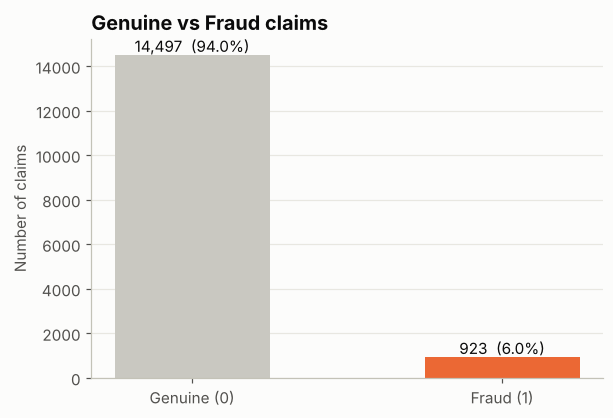

In [20]:
# BAR — Genuine vs Fraud claims
counts = df["FraudFound_P"].value_counts().sort_index()
plt.figure(figsize=(6, 4))
plt.bar(["Genuine (0)", "Fraud (1)"], counts.values, color=[GREY, ORANGE], width=0.5)
for i, v in enumerate(counts.values):
    plt.text(i, v + 150, f"{v:,}  ({v / len(df) * 100:.1f}%)", ha="center")
plt.title("Genuine vs Fraud claims")
plt.ylabel("Number of claims")
plt.grid(axis="x", visible=False)
plt.show()

In [21]:
# Distribution of a numeric column: Age
df["Age"].describe()

count    15420.000000
mean        40.665045
std         12.183501
min         16.000000
25%         31.000000
50%         39.000000
75%         48.000000
max         80.000000
Name: Age, dtype: float64

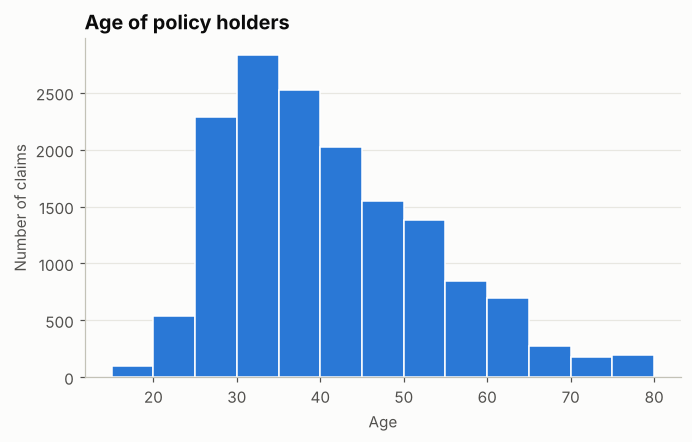

In [22]:
# HISTOGRAM — Age of policy holders
plt.figure(figsize=(7, 4))
plt.hist(df["Age"], bins=range(15, 85, 5), color=BLUE, edgecolor="white")
plt.title("Age of policy holders")
plt.xlabel("Age")
plt.ylabel("Number of claims")
plt.grid(axis="x", visible=False)
plt.show()

In [23]:
# Distribution of categorical columns
df["Fault"].value_counts()

Fault
Policy Holder    11230
Third Party       4190
Name: count, dtype: int64

In [24]:
df["PolicyType"].value_counts()

PolicyType
Sedan - Collision       5584
Sedan - Liability       4987
Sedan - All Perils      4087
Sport - Collision        348
Utility - All Perils     340
Utility - Collision       30
Sport - All Perils        22
Utility - Liability       21
Sport - Liability          1
Name: count, dtype: int64

In [25]:
df["Make"].value_counts()

Make
Pontiac      3837
Toyota       3121
Honda        2801
Mazda        2354
Chevrolet    1681
Accura        472
Ford          450
VW            283
Dodge         109
Saab          108
Mercury        83
Saturn         58
Nisson         30
BMW            15
Jaguar          6
Porche          5
Mecedes         4
Ferrari         2
Lexus           1
Name: count, dtype: int64

In [26]:
df["Deductible"].value_counts()

Deductible
400    14838
700      311
500      263
300        8
Name: count, dtype: int64

# 9.Bivariate Analysis — Which values of a column lead to fraud?

For every column we calculate the **fraud rate** = (fraud claims ÷ total claims) × 100 for each value.
The dashed line is the overall average fraud rate. **Orange bars are above average**, grey bars are below. The number of claims (**n**) is written next to every bar, because a high rate on a tiny group can be just luck — bars with **fewer than 50 claims are hatched** (do not trust them).

In [27]:
overall_rate = df["FraudFound_P"].mean() * 100

def fraud_rate_chart(col, order=None):
    # fraud rate (%) for every value of a column
    t = df.groupby(col)["FraudFound_P"].agg(["mean", "count"])
    t["rate"] = t["mean"] * 100
    if order is None:
        t = t.sort_values("rate", ascending=False)      # highest fraud rate on top
    elif order == "index":
        t = t.sort_index()                              # natural order of the values
    else:
        t = t.loc[order]                                # order given by us
    colors = [ORANGE if r > overall_rate else GREY for r in t["rate"]]
    fig, ax = plt.subplots(figsize=(8, 0.42 * len(t) + 1.8))
    bars = ax.barh(t.index.astype(str), t["rate"], color=colors, height=0.6)
    for bar, color, n in zip(bars, colors, t["count"]):
        if n < 50:                                      # very small group -> hatched bar (do not trust it)
            bar.set_facecolor("#fcfcfb"); bar.set_edgecolor(color); bar.set_hatch("////")
    ax.axvline(overall_rate, color="#52514e", linestyle="--", linewidth=1)
    for i, (r, n) in enumerate(zip(t["rate"], t["count"])):
        ax.text(r + t["rate"].max() * 0.01, i, f"{r:.1f}%  (n = {n:,})", va="center", fontsize=9,
                bbox=dict(facecolor="#fcfcfb", edgecolor="none", pad=1))
    ax.set_xlim(0, t["rate"].max() * 1.35)
    ax.invert_yaxis()
    ax.set_title(f"Fraud rate by {col}")
    ax.set_xlabel("% of claims that are fraud   (n = number of claims)\ndashed line = overall average | orange = above average | hatched = fewer than 50 claims")
    ax.grid(axis="y", visible=False)
    plt.show()

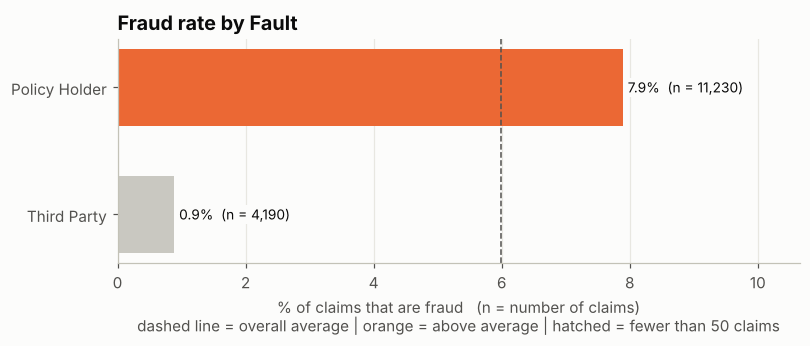

In [28]:
# Fraud rate by Fault (who caused the accident)
fraud_rate_chart("Fault")

**Insight:** when the **policy holder is at fault**, **7.9%** of claims are fraud, but when a **third party is at fault** it is only **0.9%** — about **9 times** higher. Fraudsters usually cause (or fake) their own accident.

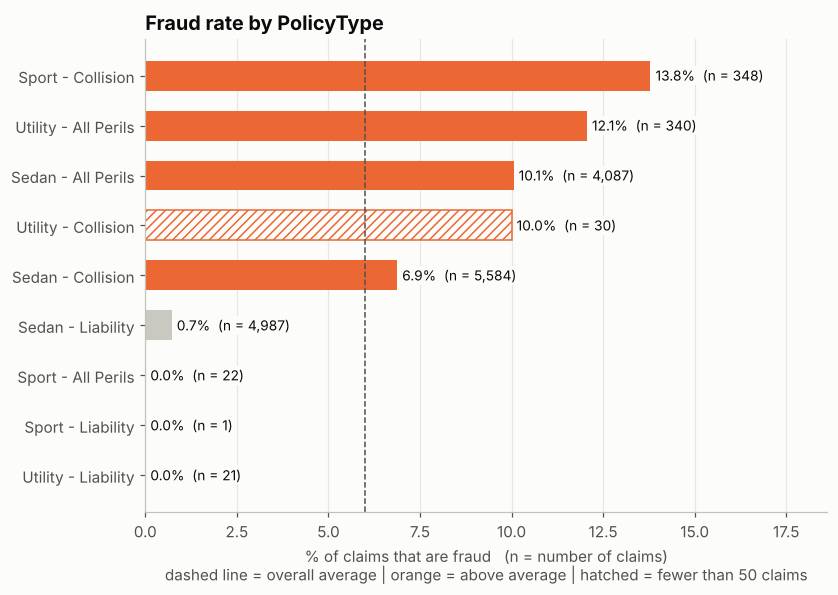

In [29]:
# Fraud rate by PolicyType
fraud_rate_chart("PolicyType")

**Insight:** **Liability** policies have almost no fraud (0.7% for Sedan - Liability), while **Collision and All Perils** policies are much higher. The highest group (with at least 100 claims) is **Sport - Collision** at **13.8%**. Policies that pay for damage to your own car are more attractive to fraudsters.

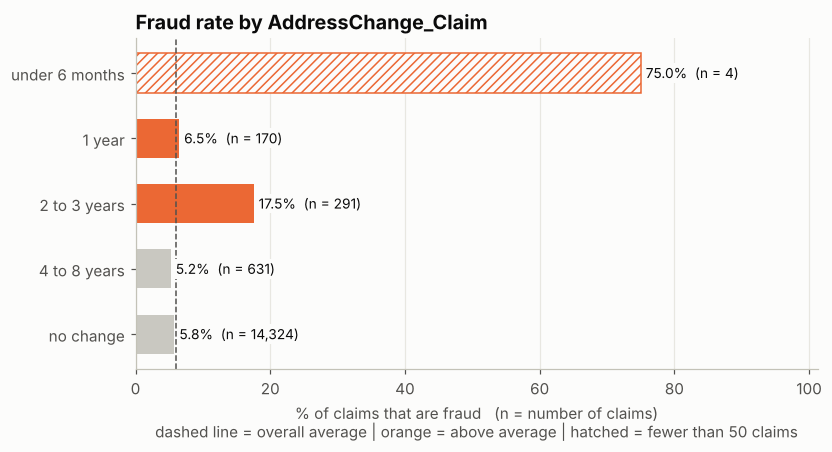

In [30]:
# Fraud rate by AddressChange_Claim (did the customer change address before the claim?)
fraud_rate_chart("AddressChange_Claim", order=["under 6 months", "1 year", "2 to 3 years", "4 to 8 years", "no change"])

**Insight:** claims made **soon after an address change** look suspicious: **under 6 months → 75%**, but this group has only **4 claims**, so be careful with the number. The bigger group **2 to 3 years → 17.5%** (291 claims) is also well above the 6.0% average.

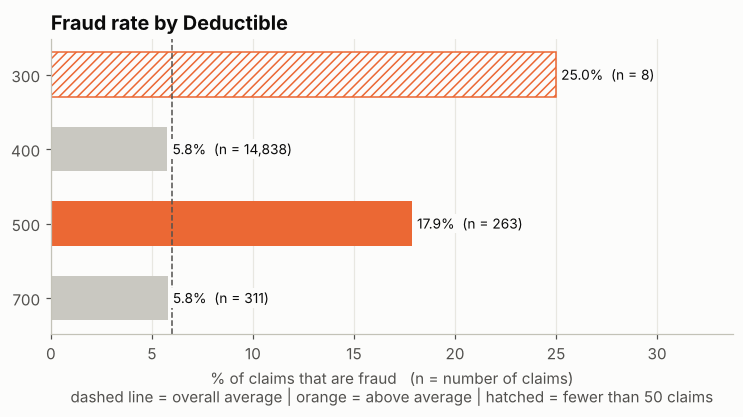

In [31]:
# Fraud rate by Deductible
fraud_rate_chart("Deductible", order="index")

**Insight:** deductibles of **300** (25%, only 8 claims) and **500** (17.9%, 263 claims) have a higher fraud rate than the common **400** (5.8%) and **700** (5.8%) deductibles.

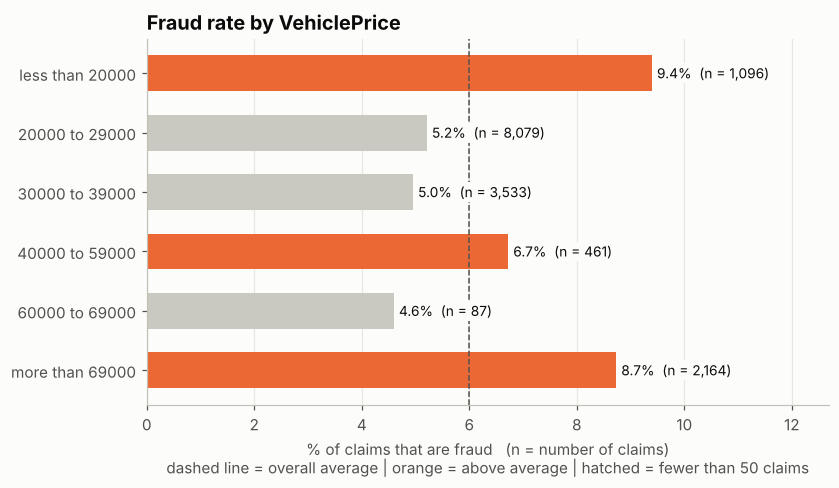

In [32]:
# Fraud rate by VehiclePrice
fraud_rate_chart("VehiclePrice", order=["less than 20000", "20000 to 29000", "30000 to 39000", "40000 to 59000", "60000 to 69000", "more than 69000"])

**Insight:** fraud is highest for vehicles priced **less than 20000** (9.4%) and lowest for **30000 to 39000** (5.0%) — the pattern is not a straight line, so price helps the model a little, but it is not a strong signal on its own.

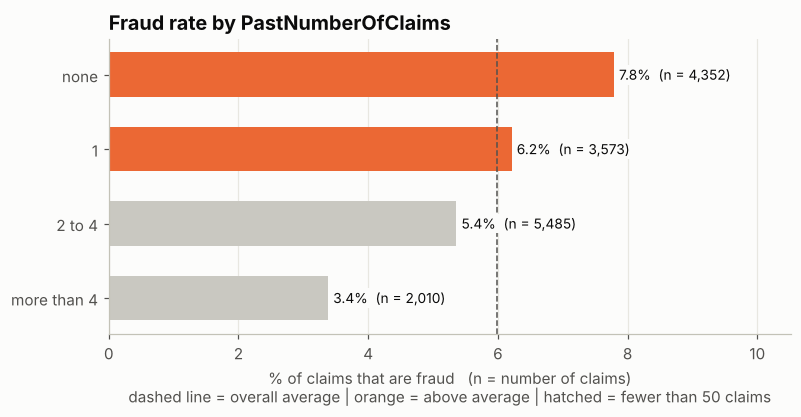

In [33]:
# Fraud rate by PastNumberOfClaims
fraud_rate_chart("PastNumberOfClaims", order=["none", "1", "2 to 4", "more than 4"])

**Insight:** a surprising result — customers with **no past claims** have the **highest** fraud rate (**7.8%**) and customers with **more than 4** past claims the lowest (**3.4%**). Fraud is not only done by "repeat claimers".

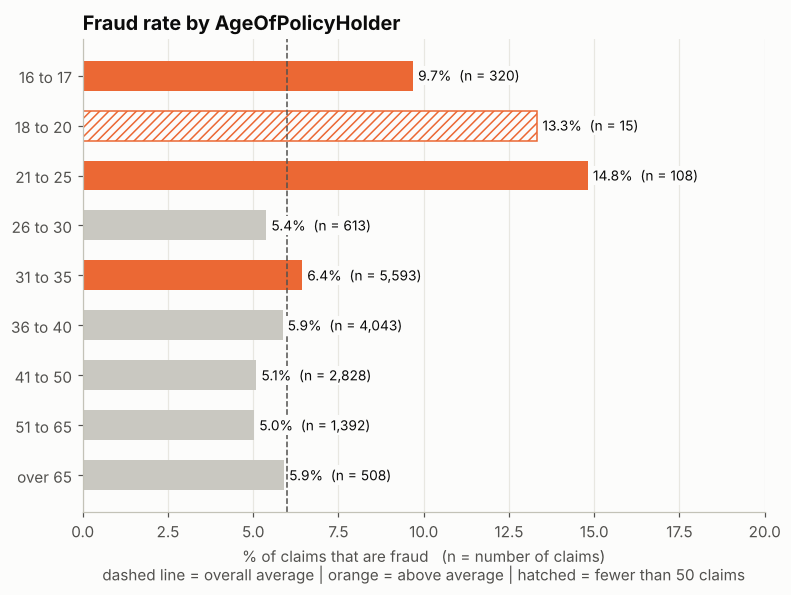

In [34]:
# Fraud rate by AgeOfPolicyHolder (age groups)
fraud_rate_chart("AgeOfPolicyHolder", order=["16 to 17", "18 to 20", "21 to 25", "26 to 30", "31 to 35", "36 to 40", "41 to 50", "51 to 65", "over 65"])

**Insight:** **young drivers (18 to 25)** have the highest fraud rate (**13.3%** and **14.8%**), about **2 to 3 times** the rate of drivers aged 26 and above (around 5 to 6%).

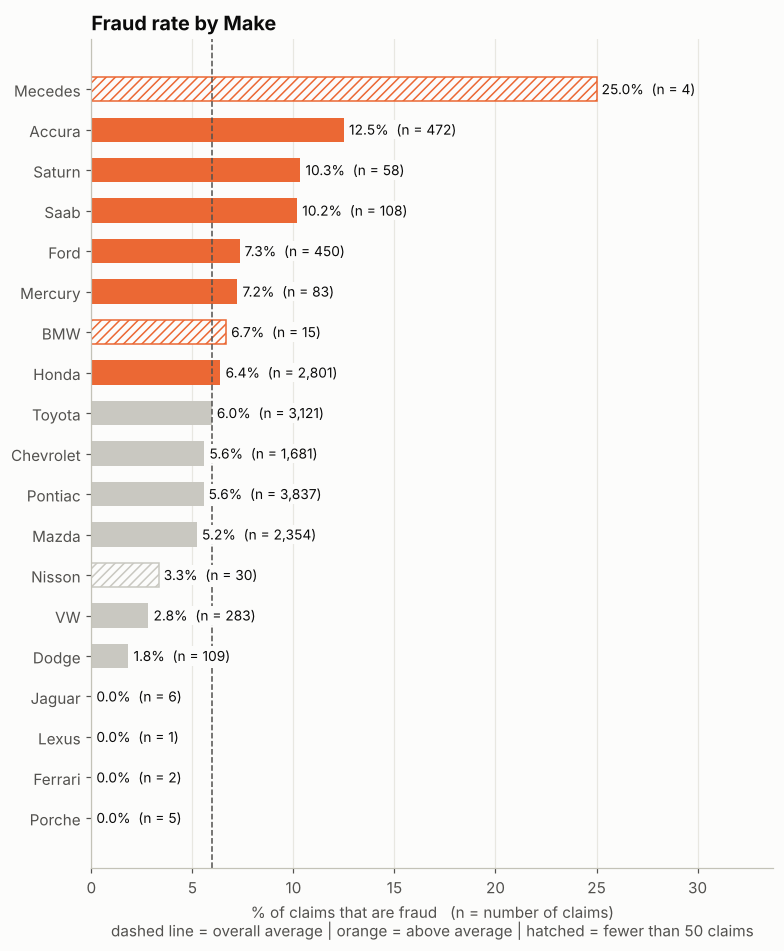

In [35]:
# Fraud rate by Make (car brand)
fraud_rate_chart("Make")

**Insight:** fraud rates vary by brand — from **12.5%** (Accura) down to **1.8%** (Dodge) among brands with at least 100 claims. Small brands with only a few claims can show extreme values by chance, so always read the claim count.

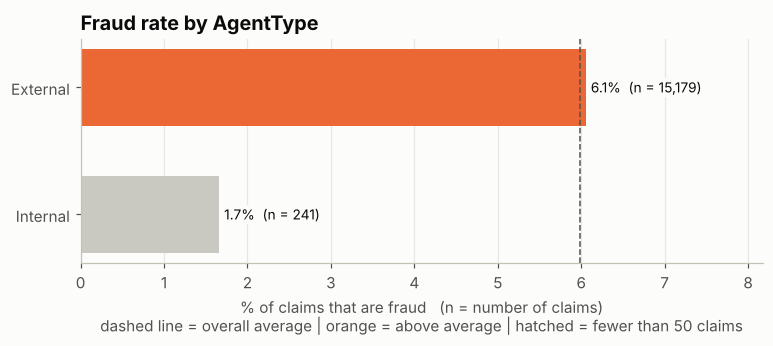

In [36]:
# Fraud rate by AgentType
fraud_rate_chart("AgentType")

**Insight:** claims handled by **External** agents have a fraud rate of **6.1%** versus **1.7%** for Internal agents, but **98%** of all claims are External, so this difference is a weaker signal than it first looks.

**Columns that do NOT matter:** the fraud rate stays almost the same for every value of these columns.

In [37]:
# Fraud rate (%) by DriverRating, MaritalStatus, WitnessPresent
for col in ["DriverRating", "MaritalStatus", "WitnessPresent"]:
    print(col)
    print((df.groupby(col)["FraudFound_P"].mean() * 100).round(1).to_string())
    print()

DriverRating
DriverRating
1    5.9
2    5.6
3    6.2
4    6.2

MaritalStatus
MaritalStatus
Divorced    3.9
Married     6.0
Single      5.9
Widow       8.6

WitnessPresent
WitnessPresent
No     6.0
Yes    3.4



**Insight:** whatever the driver rating, marital status or witness presence, the fraud rate is about 6%. These columns carry no information about fraud, so they are good candidates to remove.

# 10.Multivariate Analysis

In [38]:
# PolicyType + Fault + fraud rate together
pd.pivot_table(df, values="FraudFound_P", index="PolicyType", columns="Fault", aggfunc="mean").mul(100).round(1)

Fault,Policy Holder,Third Party
PolicyType,,
Sedan - All Perils,16.0,1.0
Sedan - Collision,9.3,1.0
Sedan - Liability,0.8,0.1
Sport - All Perils,0.0,0.0
Sport - Collision,26.6,1.7
Sport - Liability,0.0,NaN
Utility - All Perils,13.4,0.0
Utility - Collision,10.3,0.0
Utility - Liability,0.0,0.0


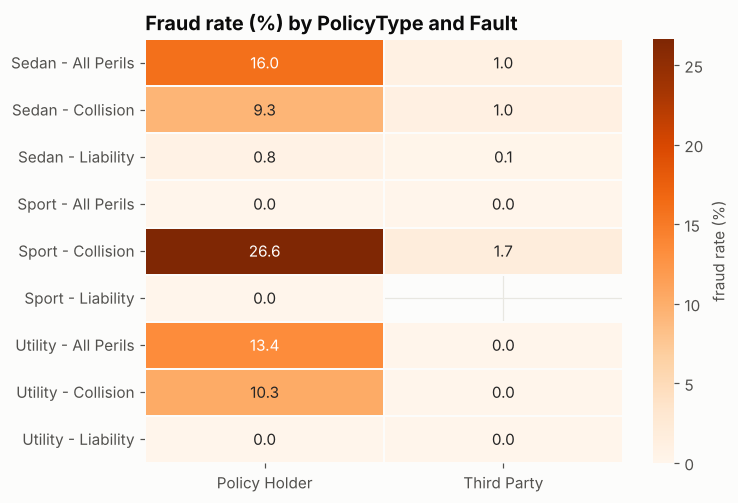

In [39]:
# HEATMAP — fraud rate (%) by PolicyType and Fault
heat = pd.pivot_table(df, values="FraudFound_P", index="PolicyType", columns="Fault", aggfunc="mean") * 100
plt.figure(figsize=(7, 5))
sns.heatmap(heat, annot=True, fmt=".1f", cmap="Oranges", linewidths=1, linecolor="#fcfcfb",
            cbar_kws={"label": "fraud rate (%)"})
plt.title("Fraud rate (%) by PolicyType and Fault")
plt.xlabel("")
plt.ylabel("")
plt.show()

**Insight:** the darkest cells are always in the **Policy Holder** column and on **Collision / All Perils** policies. For example **Sedan - All Perils** with the policy holder at fault has a fraud rate of **16.0%**, while the same policy with a third party at fault has only **1.0%**. Two factors together tell more than one.

# 11.Groupby Analysis

In [40]:
# Multiple aggregations by PolicyType
df.groupby("PolicyType").agg(
    Claims=("FraudFound_P", "count"),
    Fraud_Claims=("FraudFound_P", "sum"),
    Fraud_Rate_Percent=("FraudFound_P", lambda s: round(s.mean() * 100, 1)),
    Avg_Age=("Age", "mean"),
).round(1).sort_values("Fraud_Rate_Percent", ascending=False)

,Claims,Fraud_Claims,Fraud_Rate_Percent,Avg_Age
PolicyType,,,,
Sport - Collision,348,48,13.8,36.3
Utility - All Perils,340,41,12.1,45.8
Sedan - All Perils,4087,411,10.1,42.6
Utility - Collision,30,3,10.0,49.3
Sedan - Collision,5584,384,6.9,39.2
Sedan - Liability,4987,36,0.7,40.6
Sport - All Perils,22,0,0.0,47.7
Sport - Liability,1,0,0.0,21.0
Utility - Liability,21,0,0.0,43.4


In [41]:
# Multiple aggregations by Fault
df.groupby("Fault").agg(
    Claims=("FraudFound_P", "count"),
    Fraud_Claims=("FraudFound_P", "sum"),
    Fraud_Rate_Percent=("FraudFound_P", lambda s: round(s.mean() * 100, 1)),
)

,Claims,Fraud_Claims,Fraud_Rate_Percent
Fault,,,
Policy Holder,11230,886,7.9
Third Party,4190,37,0.9


In [42]:
# Average age of fraud vs genuine claims
df.groupby("FraudFound_P")["Age"].mean().round(1)

FraudFound_P
0    40.7
1    39.6
Name: Age, dtype: float64

# 12.Correlation Analysis

Correlation only works for numeric columns. It goes from -1 to +1, and **values near 0 mean no relation**.

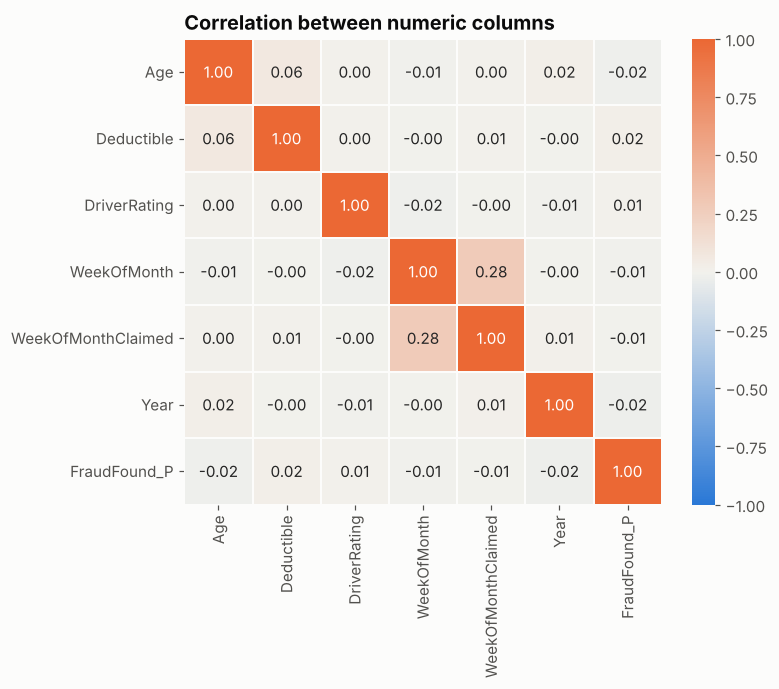

In [43]:
# HEATMAP — correlation between the numeric columns and fraud
from matplotlib.colors import LinearSegmentedColormap
diverging = LinearSegmentedColormap.from_list("blue_orange", [BLUE, "#f2f1ec", ORANGE])

num_cols_corr = ["Age", "Deductible", "DriverRating", "WeekOfMonth", "WeekOfMonthClaimed", "Year", "FraudFound_P"]
plt.figure(figsize=(7, 5.5))
sns.heatmap(df[num_cols_corr].corr(), annot=True, fmt=".2f", cmap=diverging, vmin=-1, vmax=1,
            linewidths=1, linecolor="#fcfcfb")
plt.title("Correlation between numeric columns")
plt.show()

In [44]:
# correlation of every numeric column with fraud
df[num_cols_corr].corr()["FraudFound_P"].drop("FraudFound_P").round(3)

Age                  -0.023
Deductible            0.017
DriverRating          0.007
WeekOfMonth          -0.012
WeekOfMonthClaimed   -0.006
Year                 -0.025
Name: FraudFound_P, dtype: float64

**Insight:** all numeric columns have a **very weak** relation with fraud (the strongest is **Year** with only **-0.025**). The signal for fraud is hiding mostly in the **text (category) columns**, so correlation alone is not enough — we need a method that works for categories too.

# 13.Which factors affect fraud the most?

For category columns we use **Cramér's V**. It is a score from **0 to 1** that tells how strongly a column is related to fraud:

   * 0 → the column has no relation with fraud

   * higher → stronger relation

It is built from the chi-square test (it checks whether fraud is spread evenly across the values of a column). We use the *bias-corrected* version so that columns with many values (like `Make`) are not unfairly boosted, and `Age` is first grouped into age bands.

In [45]:
from scipy.stats import chi2_contingency

def cramers_v(col):
    # Age has 65 different values, so group it into bands first
    if col == "Age":
        values = pd.cut(df[col], bins=[15, 20, 25, 30, 40, 50, 65, 100])
    else:
        values = df[col]
    table = pd.crosstab(values, df["FraudFound_P"])
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.values.sum()
    r, k = table.shape
    phi2 = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    r_c = r - (r - 1) ** 2 / (n - 1)
    k_c = k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / min(k_c - 1, r_c - 1))

In [46]:
# score for every column except the target and the ID-like columns
id_cols = ["PolicyNumber", "RepNumber", "Year"]
columns_to_rank = [c for c in df.columns if c not in ["FraudFound_P"] + id_cols]

scores = pd.Series({c: cramers_v(c) for c in columns_to_rank}).sort_values(ascending=False)
scores.round(3)

PolicyType              0.167
BasePolicy              0.161
VehicleCategory         0.137
Fault                   0.131
AddressChange_Claim     0.081
Deductible              0.067
VehiclePrice            0.064
PastNumberOfClaims      0.057
Make                    0.052
MonthClaimed            0.044
AgeOfPolicyHolder       0.040
Age                     0.039
Month                   0.035
AccidentArea            0.033
NumberOfSuppliments     0.031
AgeOfVehicle            0.031
Sex                     0.029
Days_Policy_Accident    0.022
AgentType               0.022
DayOfWeek               0.016
PoliceReportFiled       0.014
Days_Policy_Claim       0.011
WitnessPresent          0.000
DayOfWeekClaimed        0.000
WeekOfMonth             0.000
MaritalStatus           0.000
WeekOfMonthClaimed      0.000
DriverRating            0.000
NumberOfCars            0.000
dtype: float64

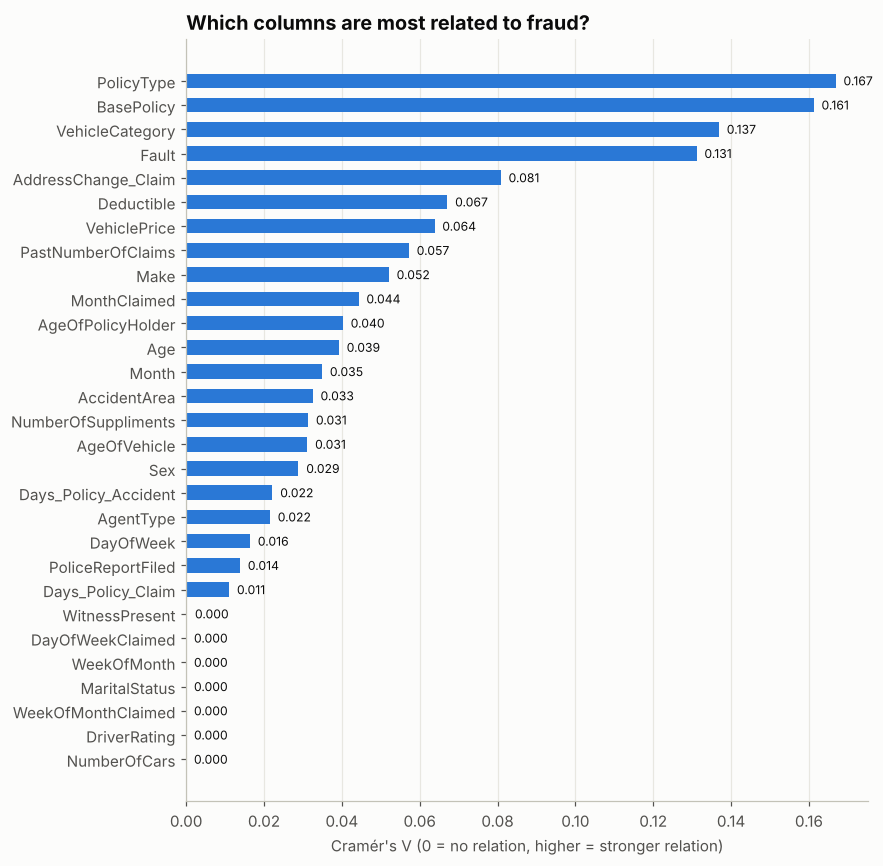

In [47]:
# BAR — strength of relation with fraud for every column
plt.figure(figsize=(8, 9))
plt.barh(scores.index[::-1], scores.values[::-1], color=BLUE, height=0.6)
for i, v in enumerate(scores.values[::-1]):
    plt.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=8)
plt.title("Which columns are most related to fraud?")
plt.xlabel("Cramér's V (0 = no relation, higher = stronger relation)")
plt.grid(axis="y", visible=False)
plt.show()

**Insight:** the factors most related to fraud are **PolicyType** (0.17), **BasePolicy** (0.16), **VehicleCategory** (0.14), **Fault** (0.13), **AddressChange_Claim** (0.08). Even the best score is small (**0.17**), which means **no single column can predict fraud alone** — the model has to combine many weak signals. Columns at the bottom (DriverRating, MaritalStatus, WeekOfMonth, NumberOfCars ...) score **0.00**: they are pure noise.

# 14.Which groups of claims lead to fraud?

We check every value of every column and keep only groups with **at least 200 claims** (so a lucky tiny group cannot fool us). Then we list the 10 groups with the highest fraud rate.

In [48]:
# fraud rate of every (column = value) group with at least 200 claims
rows = []
for col in columns_to_rank:
    if col in ["BasePolicy", "VehicleCategory"]:      # their information is already inside PolicyType (see section 16)
        continue
    t = df.groupby(col)["FraudFound_P"].agg(["mean", "count"])
    for value, r in t.iterrows():
        if r["count"] >= 200:
            rows.append([f"{col} = {value}", r["mean"] * 100, int(r["count"])])

risky = pd.DataFrame(rows, columns=["group", "fraud_rate_percent", "claims"])
risky = risky.sort_values("fraud_rate_percent", ascending=False).head(10).reset_index(drop=True)
risky.round(1)

,group,fraud_rate_percent,claims
0,Deductible = 500,17.9,263
1,AddressChange_Claim = 2 to 3 years,17.5,291
2,PolicyType = Sport - Collision,13.8,348
3,Make = Accura,12.5,472
4,PolicyType = Utility - All Perils,12.1,340
5,PolicyType = Sedan - All Perils,10.1,4087
6,AgeOfPolicyHolder = 16 to 17,9.7,320
7,VehiclePrice = less than 20000,9.4,1096
8,AgeOfVehicle = 4 years,9.2,229
9,Age = 46,9.1,296


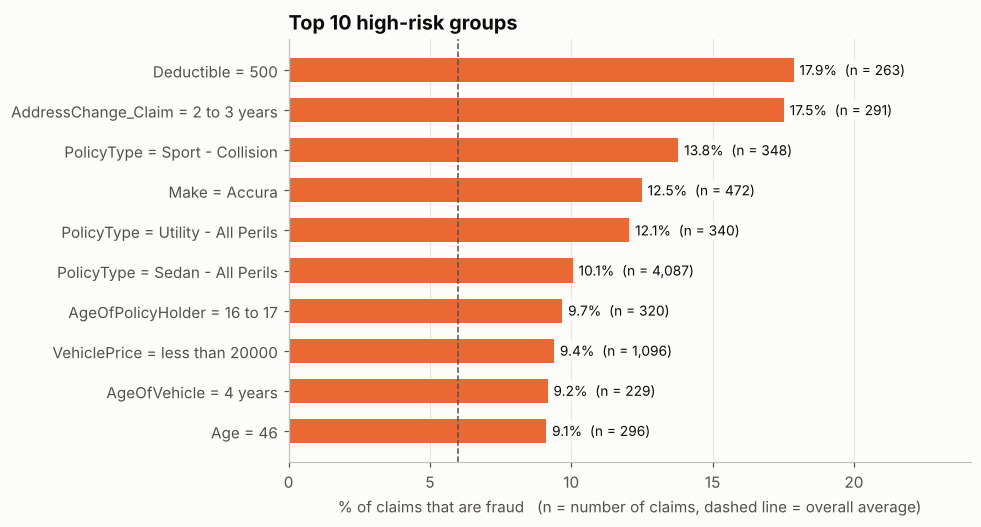

In [49]:
# BAR — top 10 high-risk groups
plt.figure(figsize=(8, 5))
plt.barh(risky["group"][::-1], risky["fraud_rate_percent"][::-1], color=ORANGE, height=0.6)
for i, (r, n) in enumerate(zip(risky["fraud_rate_percent"][::-1], risky["claims"][::-1])):
    plt.text(r + 0.2, i, f"{r:.1f}%  (n = {n:,})", va="center", fontsize=9,
             bbox=dict(facecolor="#fcfcfb", edgecolor="none", pad=1))
plt.axvline(overall_rate, color="#52514e", linestyle="--", linewidth=1)
plt.xlim(0, risky["fraud_rate_percent"].max() * 1.35)
plt.title("Top 10 high-risk groups")
plt.xlabel("% of claims that are fraud   (n = number of claims, dashed line = overall average)")
plt.grid(axis="y", visible=False)
plt.show()

**Insight:** the riskiest large groups are **Deductible = 500** (17.9%); **AddressChange_Claim = 2 to 3 years** (17.5%); **PolicyType = Sport - Collision** (13.8%); **Make = Accura** (12.5%); **PolicyType = Utility - All Perils** (12.1%). These are about **2 to 3 times** the 6.0% average. A claim that belongs to several of these groups at once should be checked first.

# 15.Business Questions

**Q1: How common is fraud?**

In [50]:
df["FraudFound_P"].value_counts(normalize=True).mul(100).round(2)

FraudFound_P
0    94.01
1     5.99
Name: proportion, dtype: float64

**Answer:** only **5.99%** of claims are fraud (923 of 15,420). Fraud is rare, so a model must be judged with recall and precision, not accuracy.

**Q2: Does it matter who is at fault?**

In [51]:
df.groupby("Fault")["FraudFound_P"].mean().mul(100).round(2)

Fault
Policy Holder    7.89
Third Party      0.88
Name: FraudFound_P, dtype: float64

**Answer:** **Yes, very much.** Policy Holder at fault → 7.9% fraud; Third Party at fault → 0.9%.

**Q3: Which policy type has the highest and the lowest fraud rate?**

In [52]:
df.groupby("PolicyType")["FraudFound_P"].mean().mul(100).round(1).sort_values(ascending=False)

PolicyType
Sport - Collision       13.8
Utility - All Perils    12.1
Sedan - All Perils      10.1
Utility - Collision     10.0
Sedan - Collision        6.9
Sedan - Liability        0.7
Sport - All Perils       0.0
Sport - Liability        0.0
Utility - Liability      0.0
Name: FraudFound_P, dtype: float64

**Answer:** among policy types with at least 100 claims, **Sport - Collision** is highest (13.8%) and **Sedan - Liability** is lowest (0.7%). All Liability policies are close to zero.

**Q4: Do young drivers commit more fraud?**

In [53]:
df.groupby("AgeOfPolicyHolder")["FraudFound_P"].mean().mul(100).round(1)

AgeOfPolicyHolder
16 to 17     9.7
18 to 20    13.3
21 to 25    14.8
26 to 30     5.4
31 to 35     6.4
36 to 40     5.9
41 to 50     5.1
51 to 65     5.0
over 65      5.9
Name: FraudFound_P, dtype: float64

**Answer:** **Yes.** Ages 18 to 25 have 13.3% to 14.8% fraud, against about 5% to 6% for ages 26 and above.

**Q5: Does an address change before the claim matter?**

In [54]:
df.groupby("AddressChange_Claim")["FraudFound_P"].agg(["mean", "count"]).assign(mean=lambda t: (t["mean"] * 100).round(1))

,mean,count
AddressChange_Claim,,
1 year,6.5,170
2 to 3 years,17.5,291
4 to 8 years,5.2,631
no change,5.8,14324
under 6 months,75.0,4


**Answer:** **Yes.** Claims within 6 months of an address change show 75% fraud, but there are only 4 such claims, so treat it as a warning sign and not a proof.

**Q6: Do numeric columns like Age, Deductible or DriverRating predict fraud?**

In [55]:
df[["Age", "Deductible", "DriverRating", "FraudFound_P"]].corr()["FraudFound_P"].round(3)

Age            -0.023
Deductible      0.017
DriverRating    0.007
FraudFound_P    1.000
Name: FraudFound_P, dtype: float64

**Answer:** **No.** All correlations are close to 0. The information is in the category columns.

# 16.Feature Reduction — from 33 columns to 12

A web page with 33 input boxes is not practical, and most columns do not help. We reduce the columns in **3 simple steps:**

**Step 1 — Remove the target and ID-like columns.**
`FraudFound_P` is the answer we want to predict. `PolicyNumber` and `RepNumber` are just ID numbers. `Year` only has the values 1994, 1995 and 1996, so a new claim will never have a useful value there.

**Step 2 — Remove columns that repeat information of another column.**

   * `BasePolicy` is the last word of `PolicyType` (it matches on **100%** of the rows).

   * `VehicleCategory` is the first word of `PolicyType` (it matches on **68%** of the rows).

   * `AgeOfPolicyHolder` is just `Age` put into groups.

**Step 3 — Rank the remaining columns (Cramér's V from section 13) and keep the top 12.**

In [56]:
# Step 1 + Step 2: columns we do not want to rank
repeated_columns = ["BasePolicy", "VehicleCategory", "AgeOfPolicyHolder"]
print("BasePolicy = last word of PolicyType in", round((df["PolicyType"].str.split(" - ").str[1] == df["BasePolicy"]).mean() * 100), "% of rows")
print("VehicleCategory = first word of PolicyType in", round((df["PolicyType"].str.split(" - ").str[0] == df["VehicleCategory"]).mean() * 100), "% of rows")

BasePolicy = last word of PolicyType in 100 % of rows
VehicleCategory = first word of PolicyType in 68 % of rows


In [57]:
# Step 3: keep the 12 best columns
remaining = scores.drop(repeated_columns)
selected = remaining.index[:12].tolist()
print("Selected 12 columns:")
for i, col in enumerate(selected, 1):
    print(i, col, round(remaining[col], 3))

Selected 12 columns:
1 PolicyType 0.167
2 Fault 0.131
3 AddressChange_Claim 0.081
4 Deductible 0.067
5 VehiclePrice 0.064
6 PastNumberOfClaims 0.057
7 Make 0.052
8 MonthClaimed 0.044
9 Age 0.039
10 Month 0.035
11 AccidentArea 0.033
12 NumberOfSuppliments 0.031


In [58]:
# the columns we throw away
dropped = [c for c in df.columns if c not in selected + ["FraudFound_P"]]
print(len(dropped), "columns removed:")
print(dropped)

20 columns removed:
['WeekOfMonth', 'DayOfWeek', 'DayOfWeekClaimed', 'WeekOfMonthClaimed', 'Sex', 'MaritalStatus', 'VehicleCategory', 'PolicyNumber', 'RepNumber', 'DriverRating', 'Days_Policy_Accident', 'Days_Policy_Claim', 'AgeOfVehicle', 'AgeOfPolicyHolder', 'PoliceReportFiled', 'WitnessPresent', 'AgentType', 'NumberOfCars', 'Year', 'BasePolicy']


**Result:** the web page needs only **12 inputs**: PolicyType, Fault, AddressChange_Claim, Deductible, VehiclePrice, PastNumberOfClaims, Make, MonthClaimed, Age, Month, AccidentArea, NumberOfSuppliments.

The columns ranked 13th and below have a relation with fraud of about 0.03 or less, i.e. almost nothing. Be honest about this: columns 8 to 12 are also weak, the first 5 or 6 are the real drivers. In the next section we **prove** that removing the other columns does not hurt the model.

# 17.Model Building

In [59]:
from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, recall_score, precision_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix, classification_report)

In [60]:
# defining dependent and independent variables of the dataset
x = df[selected]
y = df["FraudFound_P"]

In [61]:
x.head()

,PolicyType,Fault,AddressChange_Claim,Deductible,VehiclePrice,PastNumberOfClaims,Make,MonthClaimed,Age,Month,AccidentArea,NumberOfSuppliments
0,Sport - Liability,Policy Holder,1 year,300,more than 69000,none,Honda,Jan,21,Dec,Urban,none
1,Sport - Collision,Policy Holder,no change,400,more than 69000,none,Honda,Jan,34,Jan,Urban,none
2,Sport - Collision,Policy Holder,no change,400,more than 69000,1,Honda,Nov,47,Oct,Urban,none
3,Sedan - Liability,Third Party,no change,400,20000 to 29000,1,Toyota,Jul,65,Jun,Rural,more than 5
4,Sport - Collision,Third Party,no change,400,more than 69000,none,Honda,Feb,27,Jan,Urban,none


In [62]:
# split the data: 80% to train the model, 20% to test it
# stratify=y keeps the same 6% fraud share in both parts (important when fraud is rare)
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

In [63]:
print("training data shape : ", x_train.shape)
print("testing data shape  : ", x_test.shape)
print("fraud share in train: ", round(y_train.mean() * 100, 2), "%")
print("fraud share in test : ", round(y_test.mean() * 100, 2), "%")

training data shape :  (12336, 12)
testing data shape  :  (3084, 12)
fraud share in train:  5.98 %
fraud share in test :  6.0 %


### Convert text to numbers
Models understand only numbers. **One-hot encoding** turns a text column into 0/1 columns, for example `Fault` becomes `Fault_Policy Holder` (1 or 0) and `Fault_Third Party` (1 or 0). Numeric columns are only scaled. We put the converter and the model together in one **Pipeline**, so the same steps are applied automatically on new data (the API will do exactly this).

In [64]:
# which selected columns are numbers and which are text
number_cols = x.select_dtypes(include="number").columns.tolist()
text_cols = [c for c in selected if c not in number_cols]
print("number columns:", number_cols)
print("text columns  :", text_cols)

def make_converter():
    # text columns -> 0/1 columns, number columns -> scaled
    return ColumnTransformer([
        ("text", OneHotEncoder(handle_unknown="ignore", sparse_output=False), text_cols),   # sparse_output=False -> plain table
        ("number", StandardScaler(), number_cols),
    ])

number columns: ['Deductible', 'Age']
text columns  : ['PolicyType', 'Fault', 'AddressChange_Claim', 'VehiclePrice', 'PastNumberOfClaims', 'Make', 'MonthClaimed', 'Month', 'AccidentArea', 'NumberOfSuppliments']


### Three models
We use the same kind of models as in the heart disease project: Logistic Regression, Random Forest and Gradient Boosting.
`class_weight="balanced"` tells the model that **missing a fraud is worse than a false alarm**, which helps when fraud is only 6% of the data.

In [65]:
# the three models, each inside a Pipeline
models = {
    "Logistic Regression": Pipeline([("convert", make_converter()),
        ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))]),

    "Random Forest": Pipeline([("convert", make_converter()),
        ("model", RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=10,
                                         class_weight="balanced", random_state=42, n_jobs=-1))]),

    "Gradient Boosting": Pipeline([("convert", make_converter()),
        ("model", HistGradientBoostingClassifier(learning_rate=0.05, max_depth=4, max_iter=300,
                                                 class_weight="balanced", random_state=42))]),
}

### Why accuracy is not enough
Only about 6% of claims are fraud. A "model" that always answers *Not Fraud* would be **94% accurate** and would catch **zero** frauds. So we also look at:

   * **Recall** → out of all real frauds, how many did we catch?

   * **Precision** → out of the claims we flagged, how many were really fraud?

   * **ROC-AUC** → how well the model ranks fraud claims above genuine ones (0.5 = guessing, 1 = perfect).

In [66]:
# accuracy of a model that always says "Not Fraud"
print("always-Not-Fraud accuracy:", round((y_test == 0).mean() * 100, 1), "%")

always-Not-Fraud accuracy: 94.0 %


In [67]:
# train every model and test it
results = []
for name, model in models.items():
    model.fit(x_train, y_train)
    prob = model.predict_proba(x_test)[:, 1]          # fraud probability for every test claim
    pred = (prob >= 0.5).astype(int)                  # normal 0.5 cut-off for now
    validation = cross_val_score(model, x_train, y_train, cv=5, scoring="roc_auc").mean()
    results.append([name, accuracy_score(y_test, pred), recall_score(y_test, pred),
                    precision_score(y_test, pred), roc_auc_score(y_test, prob),
                    validation, average_precision_score(y_test, prob)])

results = pd.DataFrame(results, columns=["model", "accuracy", "recall", "precision",
                                         "test_roc_auc", "validation_roc_auc", "pr_auc"]).set_index("model")
results.round(3)

,accuracy,recall,precision,test_roc_auc,validation_roc_auc,pr_auc
model,,,,,,
Logistic Regression,0.628,0.903,0.129,0.809,0.807,0.159
Random Forest,0.619,0.930,0.129,0.829,0.824,0.217
Gradient Boosting,0.633,0.897,0.130,0.824,0.817,0.232


**Look at the numbers:** at the normal 0.5 cut-off the models catch most of the frauds (recall around 0.9) but they also flag many genuine claims, so precision is very low and accuracy is only about 0.6. The models are *over-cautious*. That is why we choose a better threshold in the next steps. The **ROC-AUC** and **PR-AUC** columns do not depend on the threshold, so we use them to compare the models.

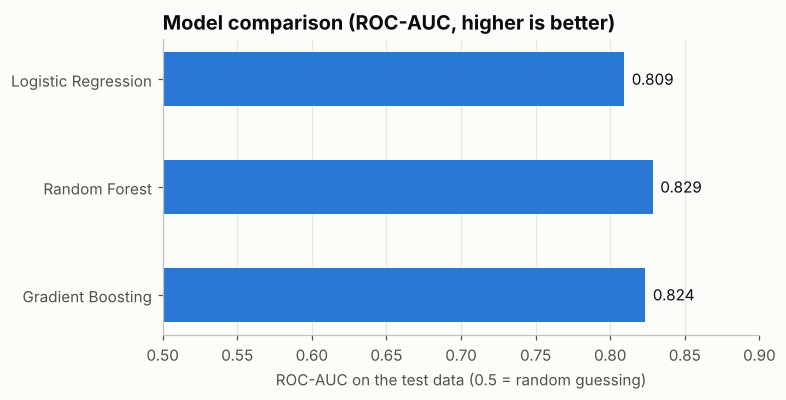

In [68]:
# BAR — compare the models (ROC-AUC on the test data)
plt.figure(figsize=(7, 3.5))
plt.barh(results.index[::-1], results["test_roc_auc"][::-1], color=BLUE, height=0.5)
for i, v in enumerate(results["test_roc_auc"][::-1]):
    plt.text(v + 0.005, i, f"{v:.3f}", va="center")
plt.xlim(0.5, 0.9)
plt.title("Model comparison (ROC-AUC, higher is better)")
plt.xlabel("ROC-AUC on the test data (0.5 = random guessing)")
plt.grid(axis="y", visible=False)
plt.show()

In [69]:
# the best model = the one with the highest PR-AUC (the fair score when fraud is rare)
best_name = results["pr_auc"].idxmax()
best_model = models[best_name]
print("Best model:", best_name)

Best model: Gradient Boosting


### Choosing the threshold
The model gives every claim a **fraud risk score between 0 and 1**. The **threshold** is how high the score must be before we call the claim *Fraud*. A low threshold catches more frauds but gives more false alarms; a high threshold does the opposite. We test several thresholds on the **training data** (using cross-validation, so the test data stays untouched) and keep the one with the best **F1 score** (balance between recall and precision).

In [70]:
# fraud scores for the training claims, predicted by models that did NOT see those claims
train_scores = cross_val_predict(best_model, x_train, y_train, cv=5, method="predict_proba")[:, 1]

rows = []
for t in np.arange(0.30, 0.90, 0.05):
    pred = (train_scores >= t).astype(int)
    rows.append([round(t, 2), recall_score(y_train, pred), precision_score(y_train, pred), f1_score(y_train, pred)])

threshold_table = pd.DataFrame(rows, columns=["threshold", "recall", "precision", "f1"]).round(3)
threshold_table

,threshold,recall,precision,f1
0,0.30,0.900,0.130,0.228
1,0.35,0.883,0.133,0.232
2,0.40,0.858,0.136,0.235
3,0.45,0.817,0.138,0.237
4,0.50,0.790,0.144,0.244
5,0.55,0.738,0.150,0.249
6,0.60,0.645,0.154,0.248
7,0.65,0.527,0.171,0.258
8,0.70,0.386,0.186,0.251
9,0.75,0.263,0.204,0.229


In [71]:
# the threshold with the best F1 score
best_threshold = float(threshold_table.loc[threshold_table["f1"].idxmax(), "threshold"])
print("Chosen threshold:", best_threshold)

Chosen threshold: 0.65


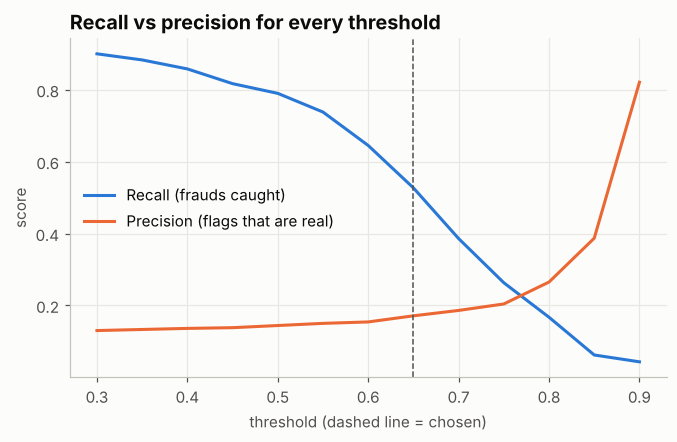

In [72]:
# LINE — recall and precision for every threshold
plt.figure(figsize=(7, 4))
plt.plot(threshold_table["threshold"], threshold_table["recall"], color=BLUE, linewidth=2, label="Recall (frauds caught)")
plt.plot(threshold_table["threshold"], threshold_table["precision"], color=ORANGE, linewidth=2, label="Precision (flags that are real)")
plt.axvline(best_threshold, color="#52514e", linestyle="--", linewidth=1)
plt.title("Recall vs precision for every threshold")
plt.xlabel("threshold (dashed line = chosen)")
plt.ylabel("score")
plt.legend(frameon=False)
plt.show()

### Final test on the 20% data the model has never seen

In [73]:
# final predictions with the chosen threshold
test_scores = best_model.predict_proba(x_test)[:, 1]
y_pred = (test_scores >= best_threshold).astype(int)

print("recall    :", round(recall_score(y_test, y_pred), 3))
print("precision :", round(precision_score(y_test, y_pred), 3))
print("ROC-AUC   :", round(roc_auc_score(y_test, test_scores), 3))
print("accuracy  :", round(accuracy_score(y_test, y_pred), 3))

recall    : 0.632
precision : 0.163
ROC-AUC   : 0.824
accuracy  : 0.783


In [74]:
print(classification_report(y_test, y_pred, target_names=["Genuine", "Fraud"]))

              precision    recall  f1-score   support

     Genuine       0.97      0.79      0.87      2899
       Fraud       0.16      0.63      0.26       185

    accuracy                           0.78      3084
   macro avg       0.57      0.71      0.57      3084
weighted avg       0.92      0.78      0.84      3084



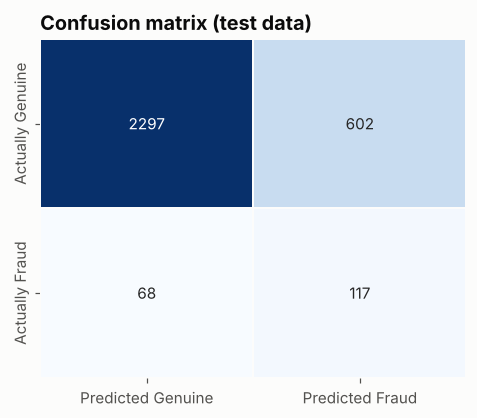

In [75]:
# HEATMAP — confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, linewidths=1, linecolor="#fcfcfb",
            xticklabels=["Predicted Genuine", "Predicted Fraud"], yticklabels=["Actually Genuine", "Actually Fraud"])
plt.title("Confusion matrix (test data)")
plt.show()

**How to read it:** the bottom row shows the real frauds — the right box is the frauds we **caught**, the left box the frauds we **missed**. The top-right box shows genuine claims we flagged by mistake (false alarms). Because fraud is rare and hard to see, precision stays low: the score should be used to **decide which claims to investigate first**, not to reject claims automatically.

### Proof that 12 columns are enough

In [76]:
# same model using ALL possible columns (everything except the ID-like columns and the target)
all_cols = [c for c in df.columns if c not in ["FraudFound_P", "PolicyNumber", "RepNumber", "Year"]]
all_num = df[all_cols].select_dtypes(include="number").columns.tolist()
all_text = [c for c in all_cols if c not in all_num]

xa_train, xa_test = df.loc[x_train.index, all_cols], df.loc[x_test.index, all_cols]
all_model = Pipeline([
    ("convert", ColumnTransformer([("text", OneHotEncoder(handle_unknown="ignore", sparse_output=False), all_text),
                                   ("number", StandardScaler(), all_num)])),
    ("model", HistGradientBoostingClassifier(learning_rate=0.05, max_depth=4, max_iter=300,
                                             class_weight="balanced", random_state=42)),
])
all_model.fit(xa_train, y_train)
all_scores = all_model.predict_proba(xa_test)[:, 1]

comparison = pd.DataFrame({
    "columns used": [len(all_cols), len(selected)],
    "ROC-AUC": [roc_auc_score(y_test, all_scores), roc_auc_score(y_test, test_scores)],
    "PR-AUC": [average_precision_score(y_test, all_scores), average_precision_score(y_test, test_scores)],
}, index=["All columns", "Selected 12 columns"]).round(3)
comparison

,columns used,ROC-AUC,PR-AUC
All columns,29,0.823,0.238
Selected 12 columns,12,0.824,0.232


**Answer:** the model with only **12 columns** scores almost the same as the model with all the columns. The other columns were just noise, so removing them makes the web page simple **without losing accuracy**.

### Which of the 12 columns does the final model use most?

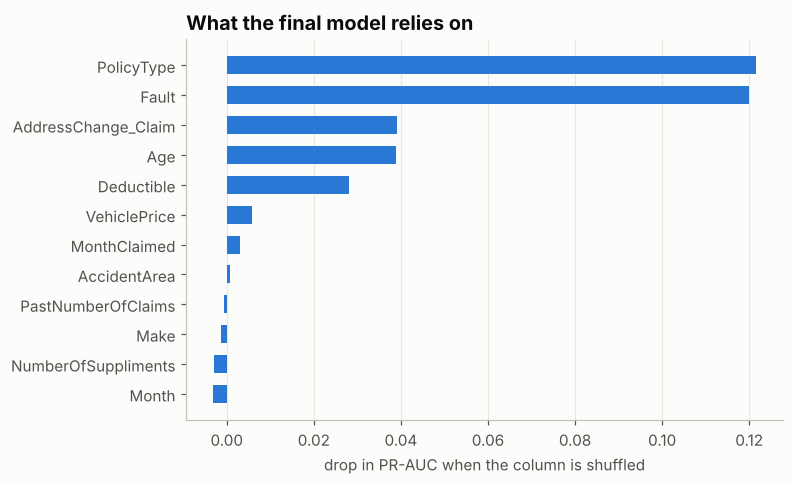

In [77]:
# Permutation importance: shuffle one column at a time and see how much the score drops.
# A big drop = the model depends on that column.
imp = permutation_importance(best_model, x_test, y_test, scoring="average_precision",
                             n_repeats=10, random_state=42, n_jobs=-1)
importance = pd.Series(imp.importances_mean, index=selected).sort_values()

plt.figure(figsize=(7, 4.5))
plt.barh(importance.index, importance.values, color=BLUE, height=0.6)
plt.title("What the final model relies on")
plt.xlabel("drop in PR-AUC when the column is shuffled")
plt.grid(axis="y", visible=False)
plt.show()

**Insight:** the model's own view agrees with the EDA — **PolicyType, Fault, AddressChange_Claim, Age and Deductible** do almost all the work. The columns at the bottom are close to zero (they even look slightly negative, which just means "no real effect"). We still keep 12 inputs because that was the requirement for the web page, but the form could be cut to the top 5 or 6 columns with almost no loss.

# 18.Save the model

In [78]:
# For the final model we use ALL the rows (more data = better model)
final_model = models[best_name]
final_model.fit(x, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('convert', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['PolicyType','Fault','AddressChange_Claim',...,'Month','AccidentArea', 'NumberOfSuppliments']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('text', ...), ('number', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder

In [79]:
# save the model, the 12 feature names and the threshold in ONE file
import joblib

joblib.dump({"model": final_model, "features": selected, "threshold": best_threshold},
            "fraud_model.joblib", compress=3)
print("saved fraud_model.joblib")

saved fraud_model.joblib


In [80]:
# library versions used for training (use the same versions in requirements.txt)
import sklearn
print("scikit-learn==" + sklearn.__version__)
print("pandas==" + pd.__version__)
print("numpy==" + np.__version__)
print("joblib==" + joblib.__version__)

scikit-learn==1.9.1
pandas==3.0.5
numpy==2.5.3
joblib==1.6.0


In [ ]:
# download the model file (Google Colab only)
try:
    from google.colab import files
    files.download("fraud_model.joblib")
except ImportError:
    print("Not in Colab - the file is already saved in this folder")

# 19.Test the saved model on one claim

In [81]:
# load the file back, exactly like the API will do
saved = joblib.load("fraud_model.joblib")

# take one real claim and keep only the 12 features
one_claim = df[saved["features"]].iloc[[0]]
one_claim.T

,0
PolicyType,Sport - Liability
Fault,Policy Holder
AddressChange_Claim,1 year
Deductible,300
VehiclePrice,more than 69000
PastNumberOfClaims,none
Make,Honda
MonthClaimed,Jan
Age,21
Month,Dec


In [82]:
score = saved["model"].predict_proba(one_claim)[0][1]
print("fraud risk score :", round(score * 100, 1), "/ 100")
print("threshold        :", round(saved["threshold"] * 100, 1))
print("result           :", "Fraud - send for investigation" if score >= saved["threshold"] else "Not fraud")

fraud risk score : 68.1 / 100
threshold        : 65.0
result           : Fraud - send for investigation


# 20.Observation → Insight → Business Impact

| Observation | Insight | Business Impact |
|---|---|---|
| Only 6.0% of claims are fraud | Fraud is rare, so accuracy is a misleading score | Use recall / precision and a fraud risk score instead of accuracy |
| Policy holder at fault → 7.9% fraud, third party at fault → 0.9% | Fault is one of the strongest signals | Review policy-holder-fault claims more closely |
| Liability policies have almost no fraud; Collision and All Perils are much higher | Policies that pay for the customer's own car attract fraud | Focus investigators on Collision / All Perils claims |
| Drivers aged 18 to 25 have 13% to 15% fraud vs about 5% for ages 26+ | Young drivers are the riskiest age group | Extra checks for young policy holders |
| Claims soon after an address change have a very high fraud rate (small group) | A recent address change is a warning sign | Verify the address and identity before paying |
| DriverRating, MaritalStatus, WeekOfMonth, NumberOfCars have no relation with fraud | 14 columns can be removed | A simple form with 12 inputs gives the same quality |
| No single column predicts fraud well (best Cramér's V = 0.17) | Fraud needs many weak signals combined | A machine learning model is needed, rules alone are not enough |

# 21.Recommendations

1. **Check Policy-Holder-fault claims on Collision / All Perils policies first.** This combination has the highest fraud rate.

2. **Add extra checks for young drivers (18 to 25)** and for claims made soon after an address change.

3. **Use the model score to rank claims, not to reject them.** The model catches a good share of the frauds, but most flagged claims are still genuine, so a human investigator must make the final decision.

4. **Collect better data.** Columns about the claim itself (claim amount, photos, repair shop, time between accident and report) would probably predict fraud far better than the policy columns we have.

5. **Keep monitoring.** Fraud patterns change over time, so retrain the model regularly with new claims.

# 22.Final Business Conclusion

This project analysed **15,420 vehicle insurance claims**, of which only **6.0%** were fraud. The EDA showed that fraud is linked mainly to **who is at fault, the policy type (Collision / All Perils), the age of the policy holder, a recent address change and the deductible**, while columns such as driver rating, marital status and week of the month have no relation with fraud.

We reduced **33 columns to 12** and showed that the model keeps the same quality. The final Gradient Boosting model gives every new claim a **fraud risk score** and is served through a **FastAPI** API with a simple **HTML page**.

The score is a **screening tool**: it helps investigators decide which claims to look at first, which saves time and money, but it does not replace human judgement.